# Climate Comfort Index · XGBoost Regressor

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Experiment notebook · predicts CCI +1, +2 and +3 days ahead*

This notebook develops the **XGBoost Regressor** model for the **Climate Comfort Index (CCI)**: pipeline stages 1-2, using the leakage-audited feature matrix produced by the preprocessing notebook.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

### Hypothesis

Gradient-boosted trees will predict CCI **more accurately than the Random Forest and both
baselines at all three horizons**, because boosting fits residuals sequentially and can exploit
weak signal that bagging averages away.

The competing possibility: with about 2,900 training rows and weak persistence at *t*+3, boosting
may overfit where bagging does not. The generalisation check (section 8) tests
this, and every score is a four-year walk-forward average, so a lucky single year cannot win.

### Design

| Choice | Value | Reason |
|:--|:--|:--|
| Algorithm | `XGBRegressor`, `hist` tree method | Strong tabular performance; fast on a dataset this size |
| Scaling | None | Trees split on thresholds, so scale is irrelevant |
| Strategy | One model per horizon (the endpoint returns three values) | Matches the deployed artefact layout |
| Selection | Optuna on walk-forward CV, all features | Section 5 |
| Objective | validation **mean absolute error (MAE)**, in CCI points (lower is better), averaged over the walk-forward folds | Used for every comparison |

### Where this notebook sits in the pipeline

| Stage | What happens | Where |
|:-:|:--|:--|
| 1–2 | Baselines, ablation and hyperparameter tuning on all features | **This notebook** |
| 3 | Shortlist the best tuned algorithms | Comparison notebook |
| 4 | Feature selection for the shortlist, then a short re-tune | Comparison notebook |
| 5–6 | Choose the champion; refit it on all development data | Comparison notebook |
| 7 | Score the champion once on the test split (2025) | Comparison notebook |
| 8 | Deploy with drift monitoring | Promotion + API |

Every score in this notebook is a **walk-forward cross-validation** average: the development split
(2016–2024) is divided into four expanding-window folds that validate on 2021, 2022, 2023 and 2024
in turn, with the embargo as a gap. A setting therefore has to work across four years, not one. The
test split is never loaded here.

### Workflow

All ten experiment notebooks run the same code from `nucleus_ml.weather.Experiment`, so their results are directly comparable. **Only the model specification in section 1 differs between notebooks.**

| # | Step | Purpose |
|:-:|:--|:--|
| 1 | Model specification | The only algorithm-specific cell |
| 2 | Data and folds | The development split and its walk-forward folds |
| 3 | Baselines | Stage 1: the floor every model must clear |
| 4 | Feature-family ablation | What each block of engineered features contributes |
| 5 | Hyperparameter tuning | Stage 2: Optuna, scored by walk-forward CV on all features |
| 6 | Cross-validated results | The model against its default and the baselines |
| 7 | Feature importance | Which features the model relies on |
| 8 | Generalisation check | Training vs validation performance |
| 9 | Save the experiment bundle | Model, CV results and specification |
| 10 | Conclusions | What to carry into the report |

---
## 0. Setup

Imports, the experiment's identity and the task definition. Everything else comes from the project package.

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
from xgboost import XGBRegressor

from nucleus_ml import FloatParameter, IntParameter
from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "comfort_climate"
EXPERIMENT = "cci_xgboost"
ALGORITHM = "XGBoost Regressor"
VERBOSE = 1  # 0 = results only, 1 = progress + every Optuna trial, 2 = every model fit
N_TRIALS = 30  # Optuna trials per target (each trial fits one model per fold)

task = wx.load_task(TASK)
print(f"{task.target_name} | {ALGORITHM} | {len(task.feature_columns)} features | "
      f"targets: {task.target_columns}")

Climate Comfort Index | XGBoost Regressor | 105 features | targets: ['cci_t1', 'cci_t2', 'cci_t3']


---
## 1. Model specification

This is the **only algorithm-specific cell**. It creates the experiment from the estimator class, which the package builds (seeding it and, where requested, scaling the features), so no helper function is needed. It also sets `default_params` (the untuned reference), a cheaper `ablation_params` and the `search_space`, written with the `nucleus_ml` parameter classes.

`max_depth` and `min_child_weight` control tree complexity and are the main defence against
overfitting. `subsample` and `colsample_bytree` add randomness, which helps with the blocks of
near-duplicate columns. `n_estimators` is tuned rather than set by early stopping, because early
stopping would use the validation split as a fitting signal on every trial.

In [14]:
DEFAULT_PARAMS = {"n_estimators": 500, "learning_rate": 0.04, "max_depth": 4,
                  "min_child_weight": 5, "subsample": 0.8, "colsample_bytree": 0.6,
                  "reg_lambda": 1.0, "reg_alpha": 0.0}

exp = wx.Experiment(
    task,
    name=EXPERIMENT,
    algorithm=ALGORITHM,
    verbose=VERBOSE,
    estimator=XGBRegressor,
    fixed={"tree_method": "hist", "n_jobs": -1, "verbosity": 0},
    default_params=DEFAULT_PARAMS,
    ablation_params={**DEFAULT_PARAMS, "n_estimators": 150, "learning_rate": 0.08},
    search_space={
        "n_estimators": IntParameter(150, 900, step=50),
        "learning_rate": FloatParameter(0.005, 0.15, log=True),
        "max_depth": IntParameter(2, 10),
        "min_child_weight": IntParameter(1, 30),
        "subsample": FloatParameter(0.5, 1.0),
        "colsample_bytree": FloatParameter(0.3, 1.0),
        "reg_lambda": FloatParameter(0.5, 50.0, log=True),
        "reg_alpha": FloatParameter(1e-3, 5.0, log=True),
    },
)

[cci_xgboost] loaded 9,099 development rows; 4 walk-forward folds; 105 features; metric mae (lower is better)


---
## 2. Data and folds

Only the **development split** (`train`, 2016–2024) is loaded. The table lists the
walk-forward folds: each trains on every year before its validation year, with the
embargo between them.

> The preprocessing notebook already applied the chronological split, the warm-up
> filter and the embargo before the test period. Nothing is shuffled here.

In [15]:
exp.data_summary()

,train_start,train_end,validate_start,validate_end,train_rows,validate_rows
fold,,,,,,
1,2000-01-31,2020-12-26,2020-12-30,2021-12-29,7636,365
2,2000-01-31,2021-12-26,2021-12-30,2022-12-29,8001,365
3,2000-01-31,2022-12-26,2022-12-30,2023-12-29,8366,365
4,2000-01-31,2023-12-26,2023-12-30,2024-12-28,8731,365


---
## 3. Baselines

Two naive forecasts, refitted on the training years of every fold and scored on its
validation year (the table shows the mean over the folds):

| Baseline | Rule | What it knows |
|:--|:--|:--|
| **Persistence** | Tomorrow's CCI equals today's CCI | The current weather, but not the season |
| **Climatology** | The average CCI for that day of the year | The season, but not the current weather |

A model must beat **both** to be worth deploying: that shows it has combined current conditions
with the seasonal cycle.

In [16]:
exp.run_baselines()

[cci_xgboost] baseline climatology     cci_t1: mean mae = 7.7886
[cci_xgboost] baseline persistence     cci_t1: mean mae = 7.2395
[cci_xgboost] baseline climatology     cci_t2: mean mae = 7.7842
[cci_xgboost] baseline persistence     cci_t2: mean mae = 9.0695
[cci_xgboost] baseline climatology     cci_t3: mean mae = 7.7788
[cci_xgboost] baseline persistence     cci_t3: mean mae = 9.9167


mae   rmse     r2  pred_std
target model                                    
cci_t1 climatology 7.789 10.406  0.002     3.712
       persistence 7.240  9.614  0.142    10.407
cci_t2 climatology 7.784 10.401  0.003     3.700
       persistence 9.069 11.788 -0.295    10.407
cci_t3 climatology 7.779 10.398  0.004     3.701
       persistence 9.917 12.783 -0.529    10.407

---
## 4. Feature-family ablation

Feature families are added **one at a time**, starting from persistence alone, and the model is cross-validated at each step with `ablation_params`. This *measures* what each block of engineering contributes; choosing features happens later, in the comparison notebook. Scores are mean MAE over the folds.

[cci_xgboost] ablation: 9 feature sets x 3 target(s) x 4 folds
[cci_xgboost] ablation persistence only (cci)              cci_t1: mae = 6.5761 (1 features)
[cci_xgboost] ablation persistence only (cci)              cci_t2: mae = 7.7071 (1 features)
[cci_xgboost] ablation persistence only (cci)              cci_t3: mae = 8.0156 (1 features)
[cci_xgboost] ablation + same_day_observations             cci_t1: mae = 6.2843 (6 features)
[cci_xgboost] ablation + same_day_observations             cci_t2: mae = 7.4844 (6 features)
[cci_xgboost] ablation + same_day_observations             cci_t3: mae = 7.7097 (6 features)
[cci_xgboost] ablation + same_day_indices                  cci_t1: mae = 6.2878 (17 features)
[cci_xgboost] ablation + same_day_indices                  cci_t2: mae = 7.4876 (17 features)
[cci_xgboost] ablation + same_day_indices                  cci_t3: mae = 7.7196 (17 features)
[cci_xgboost] ablation + lags                              cci_t1: mae = 6.3341 (49 features)
[cc

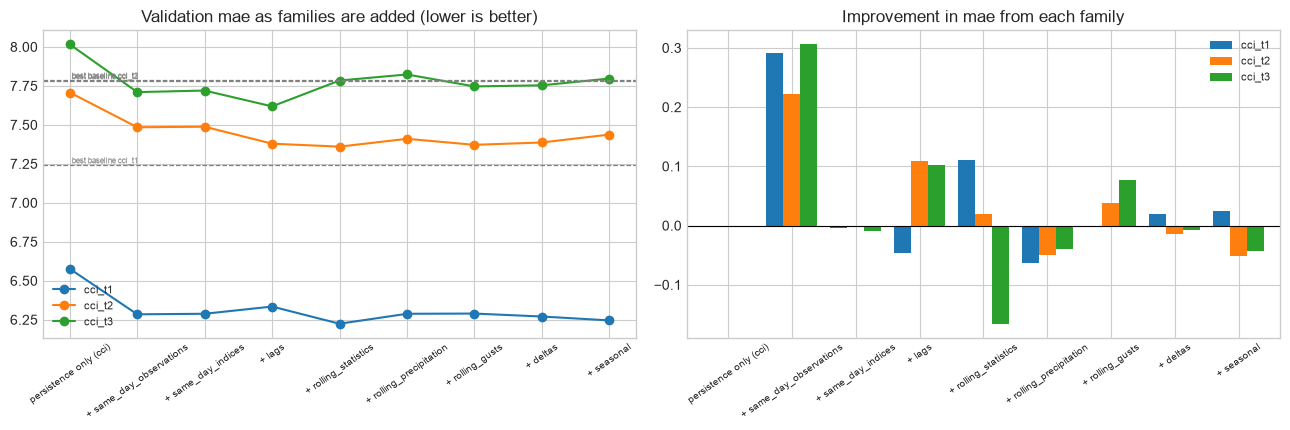

target,cci_t1,cci_t2,cci_t3,n_features
config,,,,
persistence only (cci),6.576,7.707,8.016,1
+ same_day_observations,6.284,7.484,7.710,6
+ same_day_indices,6.288,7.488,7.720,17
+ lags,6.334,7.379,7.618,49
+ rolling_statistics,6.224,7.360,7.784,89
+ rolling_precipitation,6.288,7.410,7.823,93
+ rolling_gusts,6.289,7.372,7.746,97
+ deltas,6.270,7.387,7.753,103
+ seasonal,6.245,7.437,7.797,105


In [17]:
ablation = exp.run_ablation()
plt.show()
ablation

---
## 5. Hyperparameter tuning

Optuna (seeded TPE sampler) searches the space defined in section 1, **on all
features**. Every trial is cross-validated on the four folds and scored by its
mean, so the search cannot overfit to one year. Each target is tuned separately.
The plots show the search history and which settings mattered most.

In [18]:
exp.tune(n_trials=N_TRIALS)

[cci_xgboost] tuning cci_t1: 30 trials x 4 folds


[I 2026-09-19 18:00:25,084] A new study created in memory with name: cci_xgboost_cci_t1
[I 2026-09-19 18:00:28,116] Trial 0 finished with value: 6.279153447907422 and parameters: {'n_estimators': 200, 'learning_rate': 0.015958100115314407, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.6365974786973265, 'colsample_bytree': 0.9206689385376495, 'reg_lambda': 0.6802852507039446, 'reg_alpha': 0.013787133221513578}. Best is trial 0 with value: 6.279153447907422.
[I 2026-09-19 18:00:41,092] Trial 1 finished with value: 6.606381229542863 and parameters: {'n_estimators': 900, 'learning_rate': 0.11876838817573318, 'max_depth': 4, 'min_child_weight': 30, 'subsample': 0.9817065761225814, 'colsample_bytree': 0.4016165055839879, 'reg_lambda': 6.932871909467083, 'reg_alpha': 0.5357023521579158}. Best is trial 0 with value: 6.279153447907422.
[I 2026-09-19 18:00:58,194] Trial 2 finished with value: 6.475229865936649 and parameters: {'n_estimators': 400, 'learning_rate': 0.0612923626818228, 'ma

[cci_xgboost] best cci_t1: mean mae = 6.2193 (455s)
[cci_xgboost] tuning cci_t2: 30 trials x 4 folds


[I 2026-09-19 18:08:00,031] A new study created in memory with name: cci_xgboost_cci_t2
[I 2026-09-19 18:08:02,603] Trial 0 finished with value: 7.320925542355285 and parameters: {'n_estimators': 200, 'learning_rate': 0.015958100115314407, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.6365974786973265, 'colsample_bytree': 0.9206689385376495, 'reg_lambda': 0.6802852507039446, 'reg_alpha': 0.013787133221513578}. Best is trial 0 with value: 7.320925542355285.
[I 2026-09-19 18:08:13,888] Trial 1 finished with value: 7.687681689975081 and parameters: {'n_estimators': 900, 'learning_rate': 0.11876838817573318, 'max_depth': 4, 'min_child_weight': 30, 'subsample': 0.9817065761225814, 'colsample_bytree': 0.4016165055839879, 'reg_lambda': 6.932871909467083, 'reg_alpha': 0.5357023521579158}. Best is trial 0 with value: 7.320925542355285.
[I 2026-09-19 18:08:31,128] Trial 2 finished with value: 7.537965114317686 and parameters: {'n_estimators': 400, 'learning_rate': 0.0612923626818228, 'ma

[cci_xgboost] best cci_t2: mean mae = 7.2977 (242s)
[cci_xgboost] tuning cci_t3: 30 trials x 4 folds


[I 2026-09-19 18:12:02,197] A new study created in memory with name: cci_xgboost_cci_t3
[I 2026-09-19 18:12:04,631] Trial 0 finished with value: 7.599023513047819 and parameters: {'n_estimators': 200, 'learning_rate': 0.015958100115314407, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.6365974786973265, 'colsample_bytree': 0.9206689385376495, 'reg_lambda': 0.6802852507039446, 'reg_alpha': 0.013787133221513578}. Best is trial 0 with value: 7.599023513047819.
[I 2026-09-19 18:12:16,186] Trial 1 finished with value: 8.199252383039035 and parameters: {'n_estimators': 900, 'learning_rate': 0.11876838817573318, 'max_depth': 4, 'min_child_weight': 30, 'subsample': 0.9817065761225814, 'colsample_bytree': 0.4016165055839879, 'reg_lambda': 6.932871909467083, 'reg_alpha': 0.5357023521579158}. Best is trial 0 with value: 7.599023513047819.
[I 2026-09-19 18:12:32,751] Trial 2 finished with value: 8.046344339330059 and parameters: {'n_estimators': 400, 'learning_rate': 0.0612923626818228, 'ma

[cci_xgboost] best cci_t3: mean mae = 7.5662 (180s)


,cv_mae,trials,best_params
target,,,
cci_t1,6.219,30,"{'n_estimators': 850, 'learning_rate': 0.00807..."
cci_t2,7.298,30,"{'n_estimators': 550, 'learning_rate': 0.00719..."
cci_t3,7.566,30,"{'n_estimators': 150, 'learning_rate': 0.03464..."


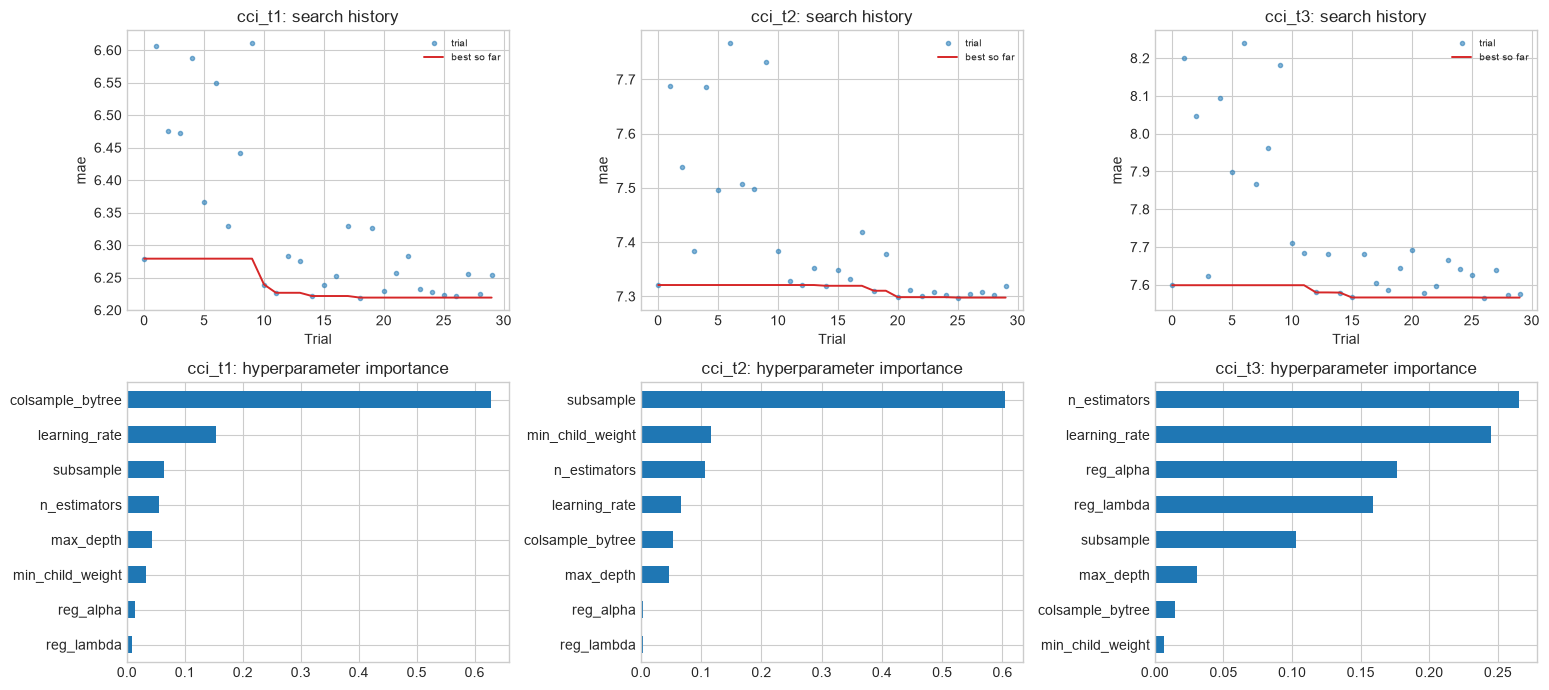

In [19]:
exp.plot_search()
plt.show()

---
## 6. Cross-validated results

The chosen configuration is cross-validated again and compared with the untuned `default` and every baseline, all on the same folds. `gain_of_model` is positive when the model beats that row. The plot shows the **out-of-fold predictions**: every validation year predicted by a model that never saw it.

`pred_std` is shown next to the error metrics. A spread far below the observed spread means the
model is playing safe by predicting close to the average, which can give a respectable MAE while
missing exactly the uncomfortable days users care about. Expect error to grow with the horizon.

In [20]:
exp.assess()

[cci_xgboost] assess cci_t1: tuned mean mae = 6.2193 (best baseline 7.2395)
[cci_xgboost] assess cci_t2: tuned mean mae = 7.2977 (best baseline 7.7842)
[cci_xgboost] assess cci_t3: tuned mean mae = 7.5662 (best baseline 7.7788)


mae   rmse     r2  pred_std  train_mae  gain_of_model
target model                                                              
cci_t1 climatology 7.789 10.406  0.002     3.712        NaN          1.569
       default     6.290  8.418  0.343     6.425      4.489          0.071
       persistence 7.240  9.614  0.142    10.407        NaN          1.020
       tuned       6.219  8.314  0.360     6.314      5.232         -0.000
cci_t2 climatology 7.784 10.401  0.003     3.700        NaN          0.487
       default     7.443  9.771  0.115     4.730      5.071          0.146
       persistence 9.069 11.788 -0.295    10.407        NaN          1.772
       tuned       7.298  9.646  0.139     4.285      6.527         -0.000
cci_t3 climatology 7.779 10.398  0.004     3.701        NaN          0.213
       default     7.811 10.203  0.038     4.567      5.187          0.245
       persistence 9.917 12.783 -0.529    10.407        NaN          2.350
       tuned       7.566  9.990  0.078     3.894      6.804         -0.000

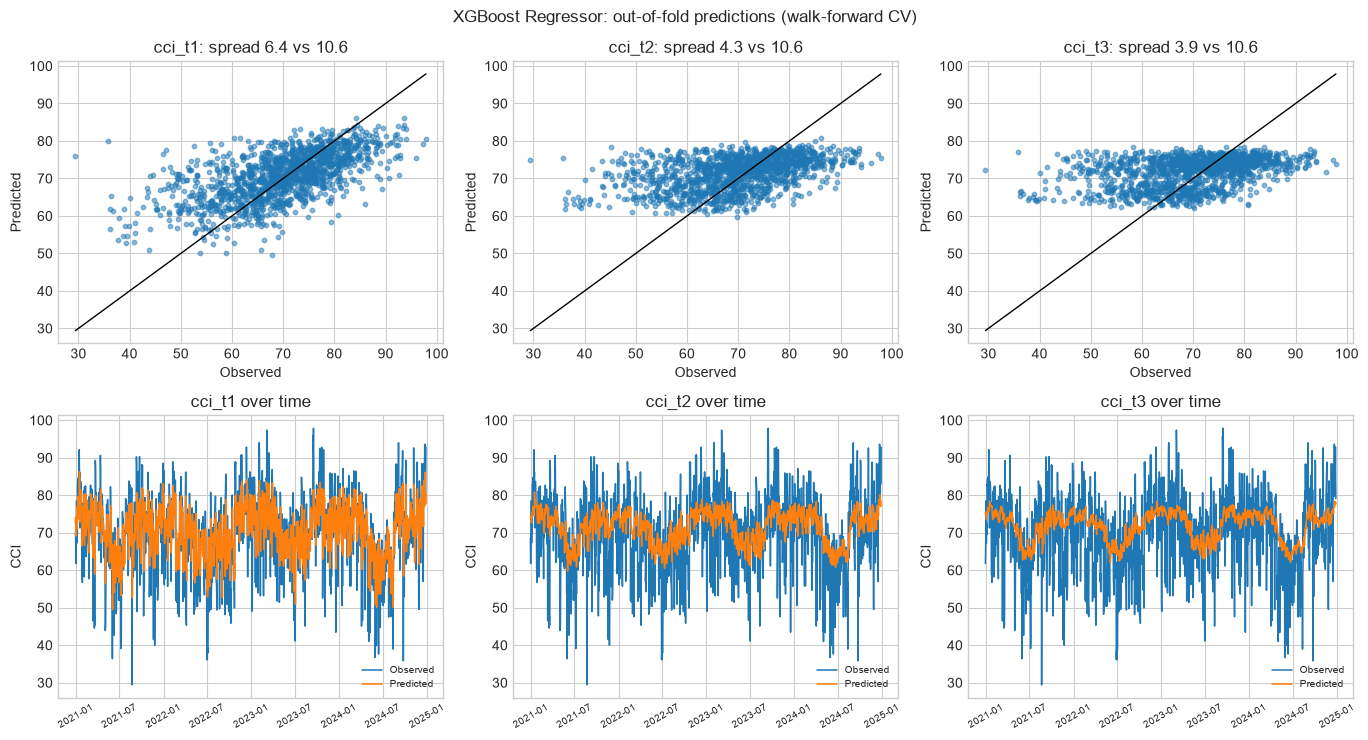

In [21]:
exp.plot_validation()
plt.show()

---
## 7. Feature importance

Tree ensembles report **impurity-based importance** directly from the fitted model. Comparing horizons is informative: features that rise in rank from *t*+1 to *t*+3 carry genuine forecast signal rather than persistence.

> Importance is measured on the last fold's model and validation year (2024). Correlated features share importance, so the ablation in section 4 is the better guide to what can be removed.

[cci_xgboost] computing feature importance (permutation importance can take a while)


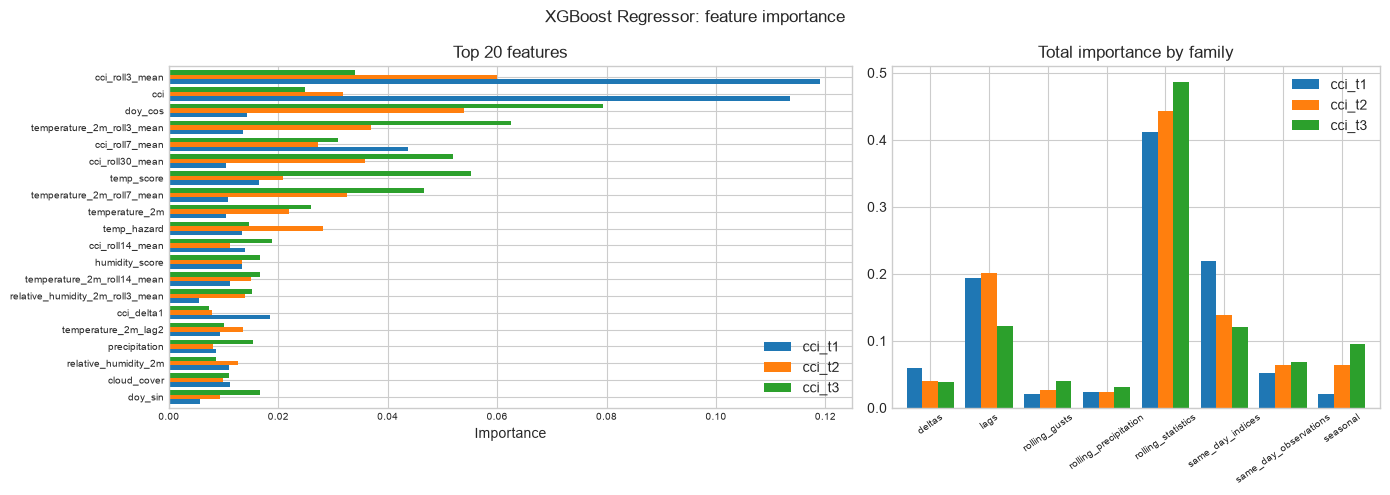

,cci_t1,cci_t2,cci_t3
deltas,0.059,0.040,0.039
lags,0.194,0.201,0.121
rolling_gusts,0.020,0.027,0.040
rolling_precipitation,0.023,0.024,0.031
rolling_statistics,0.411,0.442,0.486
same_day_indices,0.219,0.139,0.120
same_day_observations,0.053,0.064,0.068
seasonal,0.020,0.063,0.096


In [22]:
family_importance = exp.importance()
plt.show()
family_importance

---
## 8. Generalisation check

Mean training and validation scores over the folds. A small gap means the model
generalises; a large gap means it memorises the training years.

In [23]:
exp.generalisation()

,train_mae,validation_mae,validation_minus_train
target,,,
cci_t1,5.232,6.219,0.987
cci_t2,6.527,7.298,0.771
cci_t3,6.804,7.566,0.762


---
## 9. Save the experiment bundle

The chosen configuration is refitted on **all development data** and saved to
`models/comfort_climate/experiments/cci_xgboost/`:

| File | Contents |
|:--|:--|
| `cci_xgboost_h<horizon>.joblib` | The model, one per horizon |
| `metadata.json` | Settings, features, importance and the cross-validated scores |
| `manifest.json` | File list and the feature column order |
| `spec.joblib` | The specification and tuned settings, which the comparison notebook uses to rebuild this experiment |

In [24]:
exp.export()

[cci_xgboost] final fit cci_t1: 9,099 rows, 105 features
[cci_xgboost] final fit cci_t2: 9,099 rows, 105 features
[cci_xgboost] final fit cci_t3: 9,099 rows, 105 features
Saved bundle: models/comfort_climate/experiments/cci_xgboost


PosixPath('/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/models/comfort_climate/experiments/cci_xgboost')

---
## 10. Conclusions

- **Against the baselines.** The cross-validated table (section 6) is the headline. A model that
  cannot beat persistence at *t*+1 has a feature problem, not a tuning problem.
- **Overfitting.** A large train-validation gap in section 8 argues for stronger
  regularisation; compare the tuned settings with the defaults.
- **Horizon decay.** Expect the gain over the baselines to shrink from *t*+1 to *t*+3.

> If this algorithm is shortlisted, the comparison notebook selects its feature families with walk-forward cross-validation and briefly re-tunes its settings on the chosen features.

> The test split has still not been used. It is scored exactly once, in the `cci_comparison` notebook, after the champion has been chosen.